# Synora · Intentions d'achat sur un site marchand (sujet 18)

**Équipe Synora** · Machine Learning, L3 GLSI, IIT Sfax, 2026-2027.
Repérer, **pendant la visite**, les sessions d'un site marchand qui vont se terminer par un achat (Online Shoppers Purchasing Intention Dataset, UCI).

Ce notebook unique contient **tout le projet** et suit les **six étapes du cycle de vie d'un modèle** ; il sert pour les jalons J1, J2 et J3 (le tableau ci-dessous donne la partie de chaque jalon). Exécutez-le de haut en bas (*Exécution → Tout exécuter*).

| Étape | Partie du notebook | Jalon |
| --- | --- | --- |
| 1 · Collecte | Partie 1 : charger les données officielles, contrôler leur qualité, explorer | J1 |
| 2 · Préparation | Partie 2 : nettoyer, séparer train / test **avant** de préparer, encoder et normaliser | J1 |
| 3 · Modèle | Partie 3 : référence naïve et modèles candidats | J2 |
| 4 · Entraînement | Partie 4 : validation croisée avec et sans `PageValues`, meilleur seuil, `GridSearchCV` | J2 |
| 5 · Évaluation | Partie 5 : choix du seuil, évaluation **unique** sur le test, analyse des erreurs | J3 |
| 6 · Déploiement | Partie 6 : export de `model.joblib` et `requirements.txt` pour l'application Streamlit | J3 |

**Règle d'or :** le jeu de test (20 %) est mis de côté en partie 2 et n'est utilisé qu'**une seule fois**, en partie 5. Ce n'est pas une ligne droite : une évaluation décevante renvoie à la préparation des données.

**Rôles de l'équipe (ils tournent à chaque jalon)**

| Membre | Cadrage (S2) | J1 Données | J2 Modèles | J3 Évaluation et application |
| --- | --- | --- | --- | --- |
| Khaled Mnejja | Analyste données | Modélisateur | Évaluateur | Documentaliste |
| Omar Zouari | Documentaliste | Présentateur | Analyste données | Modélisateur |
| Omar Idriss | Modélisateur | Évaluateur | Documentaliste | Présentateur |
| Tawfik Zayen | Évaluateur | Documentaliste | Présentateur | Analyste données |
| Rayen Hsairi | Présentateur | Analyste données | Modélisateur | Évaluateur |

In [1]:
# Imports (toutes ces bibliothèques sont déjà installées dans Colab)
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.6.1 | pandas 2.2.3 | numpy 2.4.6


## 0. Mise en place

In [2]:
# ===================== CONFIG : tous les réglages du projet au même endroit =====================
RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 5

DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00468/online_shoppers_intention.csv"
LOCAL_PATH = "online_shoppers_intention.csv"   # utilisé si le fichier a été téléversé dans Colab

TARGET = "Revenue"
NUM_COLS = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "SpecialDay",
]
LEAKY_COL = "PageValues"   # calculée à partir des transactions : testée avec et sans
CAT_COLS = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
BOOL_COLS = ["Weekend"]

FEATURE_SETS = {
    "sans_PageValues": NUM_COLS + CAT_COLS + BOOL_COLS,
    "avec_PageValues": NUM_COLS + [LEAKY_COL] + CAT_COLS + BOOL_COLS,
}

# Garde-fou : le découpage doit toujours être le même (reproductibilité).
EXPECTED_SPLIT = (9764, 2441)   # (lignes d'entraînement, lignes de test)

In [3]:
# ===================== FONCTIONS DU PROJET =====================
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def load_raw():
    """Étape 1 : charge le CSV officiel (fichier local, sinon page UCI, sinon téléversement)."""
    if Path(LOCAL_PATH).exists():
        return pd.read_csv(LOCAL_PATH)
    try:
        return pd.read_csv(DATA_URL)
    except Exception as err:
        print("Téléchargement impossible :", err, "-> téléversez online_shoppers_intention.csv")
        from google.colab import files
        files.upload()
        return pd.read_csv(LOCAL_PATH)


def clean(df):
    """Nettoyage sans apprentissage (aucune statistique calculée) : sûr avant le découpage."""
    df = df.copy()
    df["Month"] = df["Month"].replace({"June": "Jun"})   # seul mois écrit en entier
    df["Weekend"] = df["Weekend"].astype(int)
    df[TARGET] = df[TARGET].astype(int)
    for col in CAT_COLS:                                 # les codes sont des catégories
        df[col] = df[col].astype(str)
    return df.drop_duplicates().reset_index(drop=True)   # avant le découpage, sinon fuite


def split(df):
    """Découpage stratifié, toujours avec la même graine."""
    X = df.drop(columns=TARGET)
    y = df[TARGET]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
    assert (len(X_train), len(X_test)) == EXPECTED_SPLIT, "Découpage différent de celui attendu !"
    return X_train, X_test, y_train, y_test


def make_preprocessor(feature_set):
    """Étape 2 : à n'ajuster que sur l'entraînement (ou dans un Pipeline)."""
    num = [c for c in FEATURE_SETS[feature_set] if c in NUM_COLS + [LEAKY_COL]]
    return ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
        ("bool", "passthrough", BOOL_COLS),
    ], remainder="drop")   # remainder="drop" retire PageValues dans la variante « sans »


def build_estimator(name, params=None):
    """Étape 3 : les modèles candidats."""
    estimator = {
        "Reference_naive": DummyClassifier(strategy="most_frequent"),
        "Regression_logistique": LogisticRegression(max_iter=2000, class_weight="balanced"),
        "Foret_aleatoire": RandomForestClassifier(
            n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient_boosting": HistGradientBoostingClassifier(
            class_weight="balanced", random_state=RANDOM_STATE),
    }[name]
    if params:
        estimator.set_params(**params)
    return estimator


def make_pipeline(name, feature_set, params=None):
    return Pipeline([("prep", make_preprocessor(feature_set)),
                     ("model", build_estimator(name, params))])


CV = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Partie 1 · Collecte (étape 1)

**Fiche du jeu de données**

| Rubrique | Description |
| --- | --- |
| Origine | Online Shoppers Purchasing Intention Dataset, déposé en 2018 sur l'UCI Machine Learning Repository par C. O. Sakar et al. (licence CC BY 4.0) |
| Contexte | Les visites d'un site marchand pendant une année, enregistrées par Google Analytics ; chaque ligne est une session d'un visiteur différent |
| Taille | 12 330 sessions × 18 colonnes (17 variables + 1 cible) |
| Variables | 10 numériques : pages vues et temps passé par type de page (administrative, information, produit), taux de rebond, taux de sortie, `PageValues`, `SpecialDay` ; 7 catégorielles : mois, système d'exploitation, navigateur, région, source de trafic, type de visiteur, week-end |
| Cible | `Revenue` : `True` si la session s'est terminée par un achat (environ 15 %) |
| Pièges | Classes déséquilibrées ; `PageValues` calculée à partir des achats (fuite possible) ; codes numériques qui sont des catégories ; pas de janvier ni d'avril |

### 1.1 Premier contact

In [4]:
raw = load_raw()
print(raw.shape)
raw.head()

(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


### 1.2 Qualité : types, valeurs manquantes, doublons

In [5]:
raw.info()
print("\nValeurs manquantes :", int(raw.isna().sum().sum()))
print("Lignes en double   :", int(raw.duplicated().sum()))
raw.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


#### 1.2 bis Les doublons : erreurs ou vraies visites ?

Avant de retirer les 125 doublons, regardons à quoi ils ressemblent.

In [6]:
dups = raw[raw.duplicated(keep=False)]
print("Lignes concernées par un doublon :", len(dups))
print("Dont achats :", int(dups[TARGET].sum()))
print("Pages produits (médiane) :", dups["ProductRelated"].median(),
      "| durée produits (médiane) :", dups["ProductRelated_Duration"].median(), "s")
print("Taux de rebond = 0,2 (rebond maximal) :", int((dups["BounceRates"] == 0.2).sum()), "sur", len(dups))

# Mêmes variables mais étiquette différente ? (ce serait un vrai problème de qualité)
features = [c for c in raw.columns if c != TARGET]
conflits = (raw.groupby(features)[TARGET].nunique() > 1).sum()
print("Groupes identiques avec des étiquettes contradictoires :", int(conflits))

Lignes concernées par un doublon : 201
Dont achats : 0
Pages produits (médiane) : 1.0 | durée produits (médiane) : 0.0 s
Taux de rebond = 0,2 (rebond maximal) : 201 sur 201
Groupes identiques avec des étiquettes contradictoires : 0


#### 1.2 ter Valeurs aberrantes et durées nulles

Les durées sont très étirées vers la droite : une échelle logarithmique (`log1p`) permet de voir toute la distribution.

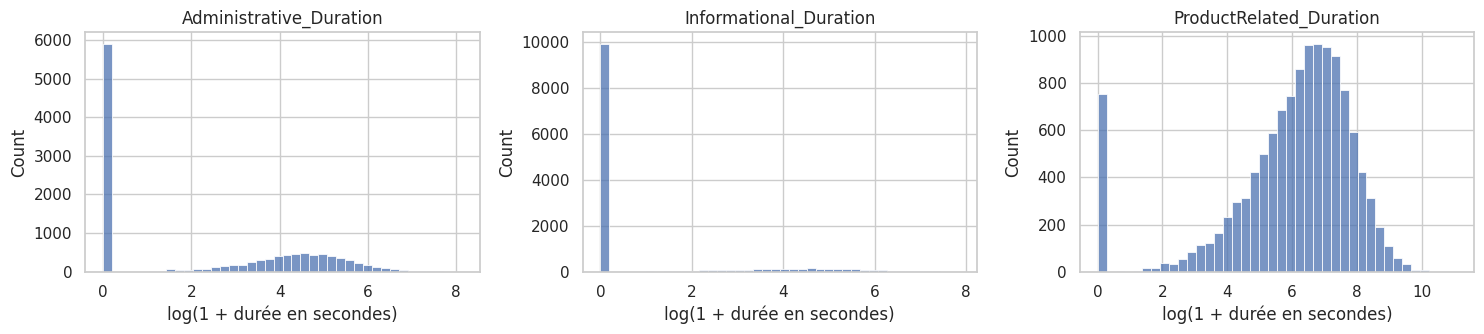

Asymétrie (skew) : {'Administrative_Duration': 5.6, 'Informational_Duration': 7.6, 'ProductRelated_Duration': 7.3}
Pages produits : médiane 10 min | 99e centile 2.4 h | max 17.8 h
Sessions de plus d'1 h sur les pages produits : 867
Sessions sans aucune page vue : 6
Administrative  pages > 0 mais durée = 0 :  135 | pages = 0 mais durée > 0 : 0
Informational   pages > 0 mais durée = 0 :  226 | pages = 0 mais durée > 0 : 0
ProductRelated  pages > 0 mais durée = 0 :  717 | pages = 0 mais durée > 0 : 0


In [7]:
DUR_COLS = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration"]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, DUR_COLS):
    sns.histplot(np.log1p(raw[col]), bins=40, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("log(1 + durée en secondes)")
plt.tight_layout()
plt.show()

print("Asymétrie (skew) :", raw[DUR_COLS].skew().round(1).to_dict())
pr = raw["ProductRelated_Duration"]
print(f"Pages produits : médiane {pr.median() / 60:.0f} min | 99e centile {pr.quantile(0.99) / 3600:.1f} h | max {pr.max() / 3600:.1f} h")
print("Sessions de plus d'1 h sur les pages produits :", int((pr > 3600).sum()))
print("Sessions sans aucune page vue :", int((raw[["Administrative", "Informational", "ProductRelated"]].sum(axis=1) == 0).sum()))

# Google Analytics ne mesure pas la durée de la dernière page vue : des pages > 0 avec une durée = 0 sont normales
for pages, duree in [("Administrative", "Administrative_Duration"), ("Informational", "Informational_Duration"),
                     ("ProductRelated", "ProductRelated_Duration")]:
    print(f"{pages:15s} pages > 0 mais durée = 0 : {int(((raw[pages] > 0) & (raw[duree] == 0)).sum()):4d}"
          f" | pages = 0 mais durée > 0 : {int(((raw[pages] == 0) & (raw[duree] > 0)).sum())}")

### 1.3 La cible : classes déséquilibrées

Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    0.845
True     0.155
Name: proportion, dtype: float64


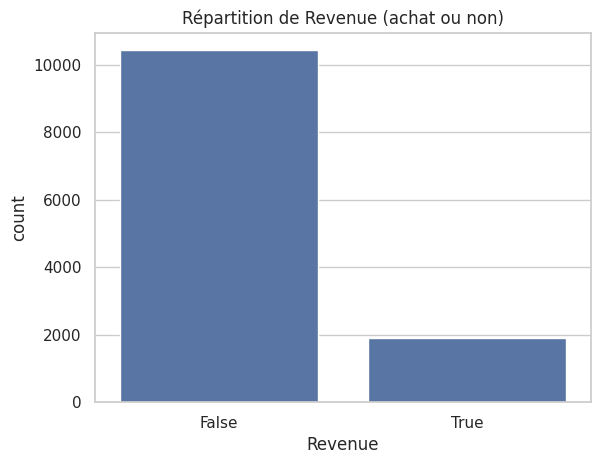

In [8]:
print(raw[TARGET].value_counts())
print(raw[TARGET].value_counts(normalize=True).round(3))
sns.countplot(x=TARGET, data=raw)
plt.title("Répartition de Revenue (achat ou non)")
plt.show()

### 1.4 Les catégories : mois et type de visiteur

In [9]:
print(raw["Month"].value_counts())       # remarque : 'June' en entier, pas de janvier ni d'avril
print(raw["VisitorType"].value_counts())

Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64
VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64


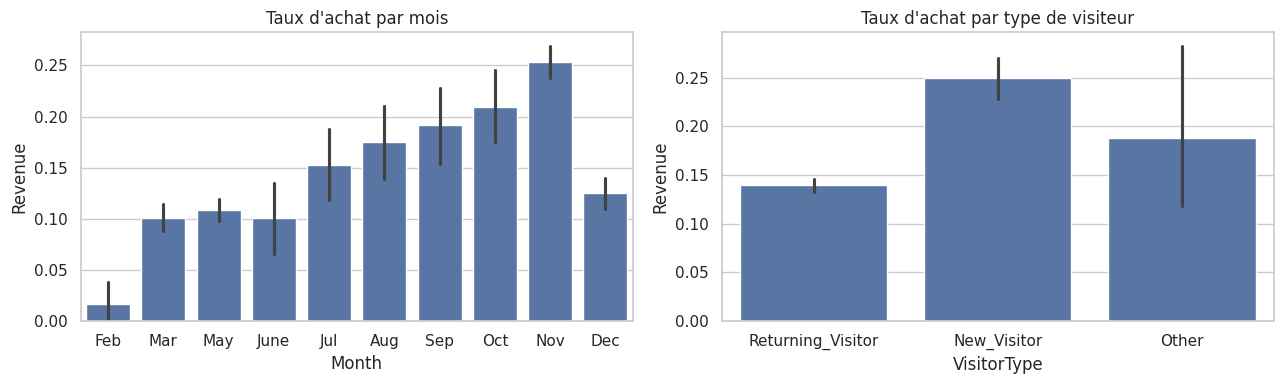

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
sns.barplot(x="Month", y=TARGET, data=raw, order=order, ax=axes[0])
axes[0].set_title("Taux d'achat par mois")
sns.barplot(x="VisitorType", y=TARGET, data=raw, ax=axes[1])
axes[1].set_title("Taux d'achat par type de visiteur")
plt.tight_layout()
plt.show()

### 1.5 Le piège `PageValues`

In [11]:
has_value = raw[LEAKY_COL] > 0
print("Taux d'achat quand PageValues > 0 :", round(raw.loc[has_value, TARGET].mean(), 3),
      "(", int(has_value.sum()), "sessions )")
print("Taux d'achat quand PageValues = 0 :", round(raw.loc[~has_value, TARGET].mean(), 3),
      "(", int((~has_value).sum()), "sessions )")

Taux d'achat quand PageValues > 0 : 0.563 ( 2730 sessions )
Taux d'achat quand PageValues = 0 : 0.039 ( 9600 sessions )


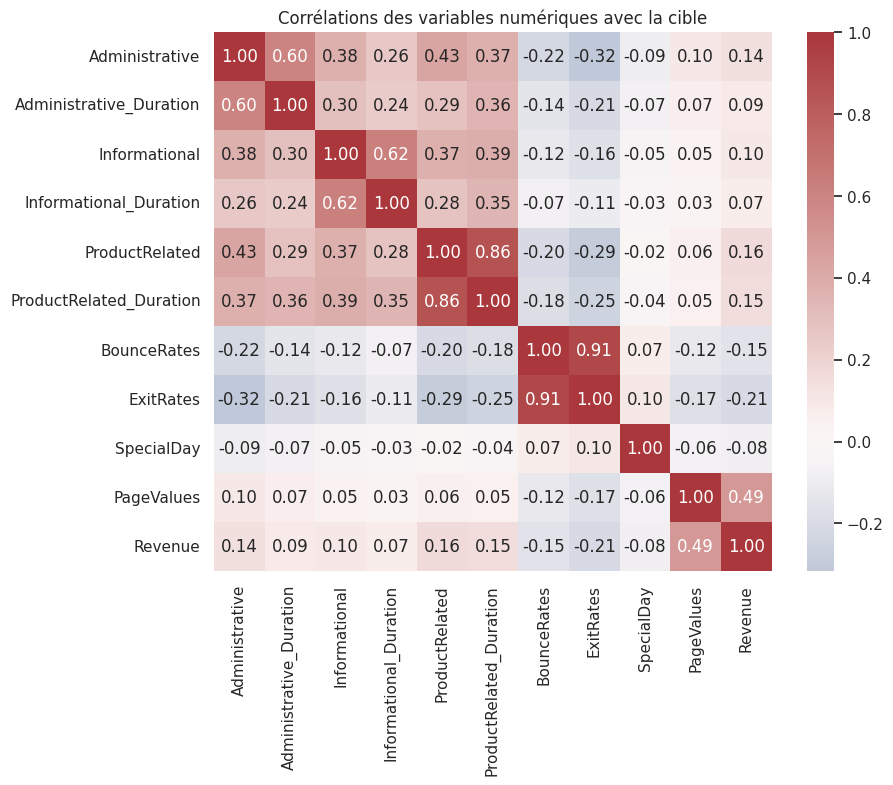

In [12]:
num = NUM_COLS + [LEAKY_COL]
plt.figure(figsize=(9, 7))
sns.heatmap(raw[num + [TARGET]].astype(float).corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Corrélations des variables numériques avec la cible")
plt.show()

### 1.5 bis Qu'est-ce qui distingue les acheteurs ?

Comparaison acheteurs / non-acheteurs sur les variables **connues pendant la visite** (donc sans `PageValues`).

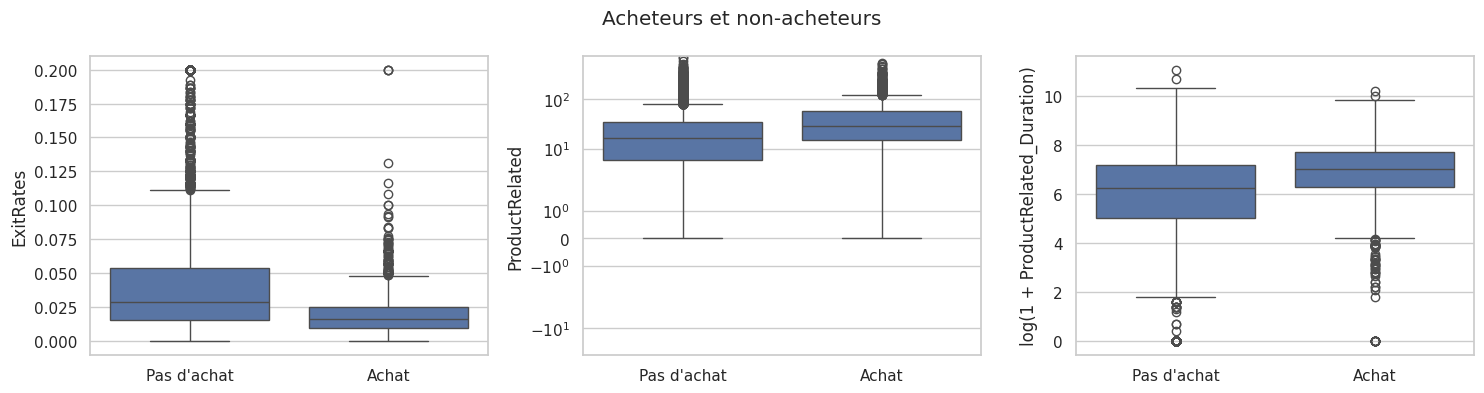

         ExitRates  BounceRates  ProductRelated  ProductRelated_Duration
Revenue                                                                 
False        0.029        0.004            16.0                  510.190
True         0.016        0.000            29.0                 1109.906

Corrélation de Spearman avec l'achat :
ExitRates                 -0.25
BounceRates               -0.15
SpecialDay                -0.09
Informational_Duration     0.11
Informational              0.11
Administrative_Duration    0.16
Administrative             0.17
ProductRelated             0.20
ProductRelated_Duration    0.22
PageValues                 0.63
dtype: float64


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x=TARGET, y="ExitRates", data=raw, ax=axes[0])
sns.boxplot(x=TARGET, y="ProductRelated", data=raw, ax=axes[1])
axes[1].set_yscale("symlog")
sns.boxplot(x=TARGET, y=np.log1p(raw["ProductRelated_Duration"]), data=raw, ax=axes[2])
axes[2].set_ylabel("log(1 + ProductRelated_Duration)")
for ax in axes:
    ax.set_xticks([0, 1], ["Pas d'achat", "Achat"])
    ax.set_xlabel("")
plt.suptitle("Acheteurs et non-acheteurs")
plt.tight_layout()
plt.show()

print(raw.groupby(TARGET)[["ExitRates", "BounceRates", "ProductRelated", "ProductRelated_Duration"]].median().round(3))

# Corrélation de Spearman (sur les rangs) : plus fiable que Pearson pour des variables très asymétriques
print("\nCorrélation de Spearman avec l'achat :")
print(raw[NUM_COLS + [LEAKY_COL]].corrwith(raw[TARGET].astype(int), method="spearman").sort_values().round(2))

### 1.5 ter Variables à surveiller : `SpecialDay` et codes rares

In [14]:
print("SpecialDay > 0 seulement pour les mois :", sorted(raw.loc[raw["SpecialDay"] > 0, "Month"].unique()))
print("(proximité de la Saint-Valentin en février et de la fête des mères en mai : redondant en partie avec Month)\n")

for col in ["OperatingSystems", "Browser", "Region", "TrafficType"]:
    counts = raw[col].value_counts()
    rares = counts[counts < 30]
    print(f"{col:16s} {len(counts):2d} codes, dont {len(rares)} rares (< 30 sessions) : {rares.to_dict()}")

SpecialDay > 0 seulement pour les mois : ['Feb', 'May']
(proximité de la Saint-Valentin en février et de la fête des mères en mai : redondant en partie avec Month)

OperatingSystems  8 codes, dont 3 rares (< 30 sessions) : {6: 19, 7: 7, 5: 6}
Browser          13 codes, dont 3 rares (< 30 sessions) : {12: 10, 11: 6, 9: 1}
Region            9 codes, dont 0 rares (< 30 sessions) : {}
TrafficType      20 codes, dont 6 rares (< 30 sessions) : {19: 17, 14: 13, 18: 10, 16: 3, 12: 1, 17: 1}


### 1.6 Constats

- **Qualité des données :** il n'y a aucune valeur manquante. On trouve 125 doublons (201 lignes concernées). En les regardant (1.2 bis), ce sont tous des rebonds (taux de rebond maximal de 0,2) sans achat, le plus souvent une seule page produit vue en 0 seconde. Ce sont donc sûrement des visites différentes qui se ressemblent, pas des erreurs de saisie. 6 sessions n'ont aucune page vue.
- **Durées :** elles sont très étalées. La moitié des visites passent moins de 10 minutes sur les pages produits, mais 867 visites dépassent 1 heure et la plus longue dure presque 18 heures (sans doute un onglet oublié). On les garde. On voit aussi 717 visites avec des pages produits vues mais une durée de 0 : sans doute parce que Google Analytics ne compte pas le temps passé sur la dernière page d'une visite (on ne peut pas le vérifier avec ces données).
- **Déséquilibre :** seulement 1 908 visites sur 12 330 finissent par un achat (15,5 %). Un modèle qui dirait toujours « pas d'achat » aurait 84,5 % de bonnes réponses sans trouver un seul acheteur. C'est pour ça qu'on regardera le rappel et le F1 sur les achats, pas l'exactitude.
- **`PageValues` :** quand elle est supérieure à 0, 56 % des visites achètent ; quand elle vaut 0, seulement 4 %. C'est la variable la plus liée à l'achat (0,63 en Spearman). Le problème : elle est calculée avec les achats, donc on ne la connaît pas vraiment pendant la visite. On fera les modèles avec et sans elle pour voir la différence.
- **Ce qui distingue les acheteurs (1.5 bis) :** ils regardent presque deux fois plus de pages produits (29 contre 16 en médiane), y restent plus longtemps et quittent moins vite le site (`ExitRates` : −0,25).
- **Mois et visiteurs :** il manque janvier et avril, et « June » était écrit en entier. D'après les graphiques de la section 1.4, on achète beaucoup plus en novembre qu'en février, et les nouveaux visiteurs achètent plus souvent que les habitués. `SpecialDay` n'apparaît qu'en février et en mai, donc elle répète en partie l'information du mois.
- **Codes en nombres :** `OperatingSystems`, `Browser`, `Region` et `TrafficType` sont des codes, pas des quantités : la région 8 n'est pas « plus » que la région 2. On les encode en one-hot. 12 codes ont moins de 30 visites ; on les garde pour l'instant.

# Partie 2 · Préparation (étape 2)

### 2.1 Nettoyage sans apprentissage

**Pourquoi retirer les doublons alors que ce sont probablement de vraies visites (section 1.2 bis) ?** Une même ligne pourrait se retrouver à la fois dans l'entraînement et dans le test : le modèle serait alors évalué sur des exemples déjà vus (fuite). Les 125 lignes retirées sont toutes des rebonds sans achat ; l'effet sur la répartition est négligeable (15,5 % → 15,6 % d'achats). Choix prudent, assumé.

In [15]:
df = clean(raw)
print("Lignes avant :", len(raw), "| après suppression des doublons :", len(df))
print(sorted(df["Month"].unique()))

Lignes avant : 12330 | après suppression des doublons : 12205
['Aug', 'Dec', 'Feb', 'Jul', 'Jun', 'Mar', 'May', 'Nov', 'Oct', 'Sep']


### 2.2 Séparer **avant** de préparer

Le découpage est stratifié pour garder environ 15 % d'achats dans le train **et** dans le test.

In [16]:
X_train, X_test, y_train, y_test = split(df)
print("Entraînement :", X_train.shape, "| Test :", X_test.shape)
print("Taux d'achat train :", round(y_train.mean(), 3), "| test :", round(y_test.mean(), 3))

Entraînement : (9764, 17) | Test : (2441, 17)
Taux d'achat train : 0.156 | test : 0.156


### 2.3 Encoder et normaliser avec un `ColumnTransformer`

`fit` sur l'entraînement uniquement ; le test est seulement **transformé**.

In [17]:
for name in FEATURE_SETS:
    prep = make_preprocessor(name)
    Xtr = prep.fit_transform(X_train)
    Xte = prep.transform(X_test)
    print(f"{name:16s} -> train {Xtr.shape} | test {Xte.shape}")

prep = make_preprocessor("sans_PageValues").fit(X_train)
print("\nExemples de colonnes créées :", list(prep.get_feature_names_out()[:12]))

sans_PageValues  -> train (9764, 72) | test (2441, 72)
avec_PageValues  -> train (9764, 73) | test (2441, 73)

Exemples de colonnes créées : ['num__Administrative', 'num__Administrative_Duration', 'num__Informational', 'num__Informational_Duration', 'num__ProductRelated', 'num__ProductRelated_Duration', 'num__BounceRates', 'num__ExitRates', 'num__SpecialDay', 'cat__Month_Aug', 'cat__Month_Dec', 'cat__Month_Feb']


### 2.4 Préparer une nouvelle session (comme le fera l'application)

In [18]:
nouvelle_session = X_test.iloc[[0]]
display(nouvelle_session)
print(prep.transform(nouvelle_session).round(2))

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
11640,0,0.0,0,0.0,12,482.5,0.02,0.04,0.0,0.0,Nov,1,2,1,10,Returning_Visitor,0


[[-0.7  -0.46 -0.4  -0.24 -0.45 -0.38 -0.01 -0.03 -0.31  0.    0.    0.
   0.    0.    0.    0.    1.    0.    0.    0.    0.    1.    1.    0.
   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    1.
   0.    0.    0.    0.    0.    0.    0.    1.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    1.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.  ]]


## Bilan J1

- **Ce qu'on a appris :** les données viennent d'un seul site sur un an (sans janvier ni avril). Elles sont propres mais déséquilibrées : 15,5 % d'achats. Les acheteurs regardent plus de pages produits et partent moins vite. `PageValues` prédit très bien l'achat, mais elle pose un risque de fuite.
- **Nos choix de préparation :** on a retiré les doublons avant de découper, pour qu'une même ligne ne se retrouve pas à la fois dans l'entraînement et dans le test (ça change très peu : 15,5 % → 15,6 % d'achats). On a découpé en 80 / 20 en gardant la même proportion d'achats (`stratify`, graine 42), **avant** de préparer. Ensuite, `StandardScaler` pour les nombres et `OneHotEncoder` pour les codes, appris uniquement sur l'entraînement. On obtient 9 764 visites pour entraîner et 2 441 pour tester ; le test reste de côté jusqu'à la partie 5.
- **Pour la suite (J2) :** comparer les modèles avec et sans `PageValues`.

# Partie 3 · Modèle (étape 3)

| Modèle | Pourquoi l'essayer |
| --- | --- |
| Référence naïve | Prédit toujours « pas d'achat » : le score à battre |
| Régression logistique | Simple, rapide, interprétable |
| Forêt aléatoire | Capte les interactions sans normalisation |
| Gradient boosting | Souvent le plus performant sur des données tabulaires |

Tous les modèles (sauf la référence) utilisent `class_weight="balanced"` à cause des 15 % d'achats.

In [19]:
MODELS = ["Reference_naive", "Regression_logistique", "Foret_aleatoire", "Gradient_boosting"]
SCORING = {"f1": "f1", "rappel": "recall", "precision": "precision", "auc": "roc_auc"}

# Partie 4 · Entraînement (étape 4)

### 4.1 Validation croisée de tous les modèles, avec et sans `PageValues`

In [20]:
from sklearn.model_selection import cross_validate

rows = []
for feature_set in FEATURE_SETS:
    for name in MODELS:
        scores = cross_validate(make_pipeline(name, feature_set), X_train, y_train,
                                cv=CV, scoring=SCORING, n_jobs=-1)
        row = {"variables": feature_set, "modele": name}
        for metric in SCORING:
            values = scores[f"test_{metric}"]
            row[metric] = f"{values.mean():.3f} ± {values.std():.3f}"
            row[f"_{metric}"] = values.mean()
        rows.append(row)
        print(f"{feature_set:16s} {name:22s} F1 = {row['f1']}")

results = pd.DataFrame(rows)
display(results[["variables", "modele", "f1", "rappel", "precision", "auc"]])

sans_PageValues  Reference_naive        F1 = 0.000 ± 0.000
sans_PageValues  Regression_logistique  F1 = 0.392 ± 0.011
sans_PageValues  Foret_aleatoire        F1 = 0.138 ± 0.032
sans_PageValues  Gradient_boosting      F1 = 0.411 ± 0.009
avec_PageValues  Reference_naive        F1 = 0.000 ± 0.000
avec_PageValues  Regression_logistique  F1 = 0.606 ± 0.024
avec_PageValues  Foret_aleatoire        F1 = 0.614 ± 0.016
avec_PageValues  Gradient_boosting      F1 = 0.669 ± 0.015


,variables,modele,f1,rappel,precision,auc
0,sans_PageValues,Reference_naive,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
1,sans_PageValues,Regression_logistique,0.392 ± 0.011,0.734 ± 0.014,0.267 ± 0.009,0.744 ± 0.022
2,sans_PageValues,Foret_aleatoire,0.138 ± 0.032,0.079 ± 0.020,0.565 ± 0.085,0.769 ± 0.014
3,sans_PageValues,Gradient_boosting,0.411 ± 0.009,0.604 ± 0.023,0.312 ± 0.006,0.765 ± 0.011
4,avec_PageValues,Reference_naive,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
5,avec_PageValues,Regression_logistique,0.606 ± 0.024,0.752 ± 0.028,0.508 ± 0.023,0.899 ± 0.012
6,avec_PageValues,Foret_aleatoire,0.614 ± 0.016,0.512 ± 0.020,0.768 ± 0.009,0.926 ± 0.003
7,avec_PageValues,Gradient_boosting,0.669 ± 0.015,0.782 ± 0.026,0.585 ± 0.018,0.926 ± 0.006


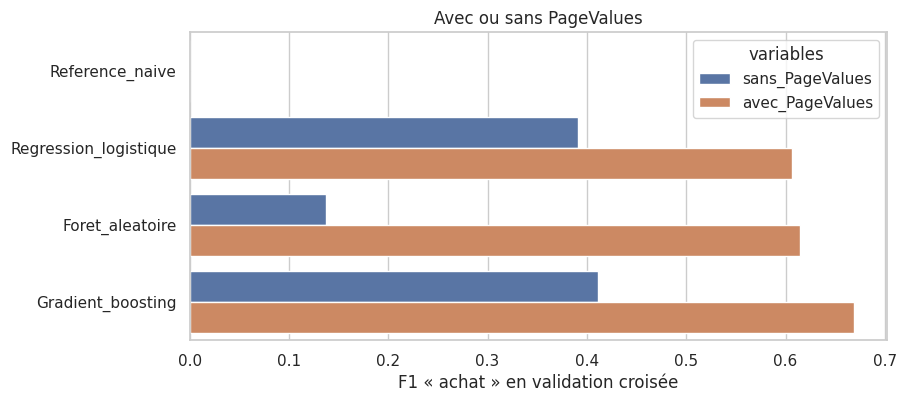

In [21]:
plt.figure(figsize=(9, 4))
sns.barplot(x="_f1", y="modele", hue="variables", data=results)
plt.xlabel("F1 « achat » en validation croisée")
plt.ylabel("")
plt.title("Avec ou sans PageValues")
plt.show()

### 4.1 bis Comparer chaque modèle à son meilleur seuil

Le F1 de la section 4.1 est calculé au seuil de 0,5 : un modèle qui donne des probabilités prudentes (comme la forêt aléatoire) prédit alors presque jamais « achat » et paraît mauvais, alors qu'il **classe** peut-être bien les sessions (voir son AUC). Comme la partie 5 choisira de toute façon le seuil, il est plus juste de comparer les modèles **chacun à son meilleur seuil**.

Tout se fait en validation croisée sur l'entraînement (`cross_val_predict`) : **le test n'est toujours pas utilisé**. On ajoute aussi la précision moyenne (`average_precision`), un score qui ne dépend d'aucun seuil et qui convient aux classes déséquilibrées.

,variables,modele,"F1 au seuil 0,5 (moy. ± écart-type)",F1 au meilleur seuil
0,sans_PageValues,Reference_naive,0.000 ± 0.000,NaN
1,sans_PageValues,Regression_logistique,0.392 ± 0.011,0.393
2,sans_PageValues,Foret_aleatoire,0.138 ± 0.032,0.414
3,sans_PageValues,Gradient_boosting,0.411 ± 0.009,0.418
4,avec_PageValues,Reference_naive,0.000 ± 0.000,NaN
5,avec_PageValues,Regression_logistique,0.606 ± 0.024,0.637
6,avec_PageValues,Foret_aleatoire,0.614 ± 0.016,0.690
7,avec_PageValues,Gradient_boosting,0.669 ± 0.015,0.678


,variables,modele,seuil,f1_seuil,rappel_seuil,precision_seuil,precision_moyenne
0,sans_PageValues,Regression_logistique,0.600,0.393,0.546,0.307,0.318
1,sans_PageValues,Foret_aleatoire,0.240,0.414,0.514,0.346,0.367
2,sans_PageValues,Gradient_boosting,0.526,0.418,0.578,0.327,0.358
3,avec_PageValues,Regression_logistique,0.647,0.637,0.641,0.634,0.645
4,avec_PageValues,Foret_aleatoire,0.323,0.690,0.737,0.649,0.740
5,avec_PageValues,Gradient_boosting,0.606,0.678,0.731,0.632,0.739


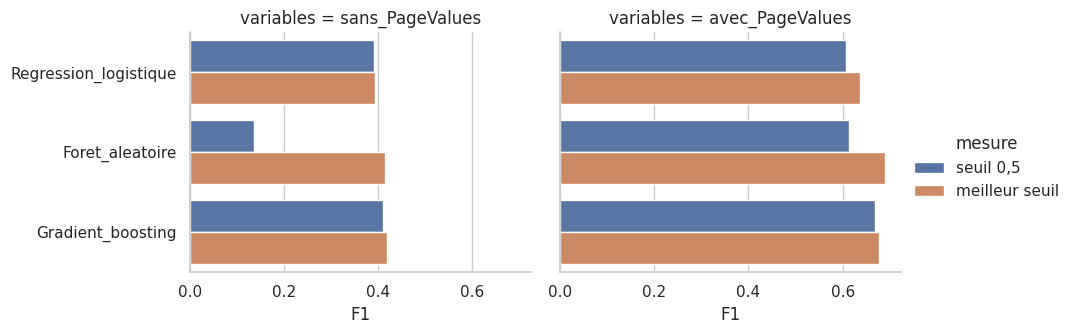

In [22]:
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.model_selection import cross_val_predict

rows_seuil = []
for feature_set in FEATURE_SETS:
    for name in MODELS[1:]:   # la référence naïve n'a pas de probabilités utiles
        proba = cross_val_predict(make_pipeline(name, feature_set), X_train, y_train,
                                  cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
        precision, recall, thresholds = precision_recall_curve(y_train, proba)
        f1 = 2 * precision * recall / (precision + recall + 1e-12)
        i = int(np.argmax(f1[:-1]))
        rows_seuil.append({"variables": feature_set, "modele": name,
                           "seuil": round(float(thresholds[i]), 3),
                           "f1_seuil": round(float(f1[i]), 3),
                           "rappel_seuil": round(float(recall[i]), 3),
                           "precision_seuil": round(float(precision[i]), 3),
                           "precision_moyenne": round(average_precision_score(y_train, proba), 3)})

results_seuil = pd.DataFrame(rows_seuil)
results = results.merge(results_seuil[["variables", "modele", "f1_seuil"]], on=["variables", "modele"], how="left")
display(results[["variables", "modele", "f1", "f1_seuil"]].rename(
    columns={"f1": "F1 au seuil 0,5 (moy. ± écart-type)", "f1_seuil": "F1 au meilleur seuil"}))
display(results_seuil)

plot = results.dropna(subset=["f1_seuil"]).melt(id_vars=["variables", "modele"], value_vars=["_f1", "f1_seuil"],
                                                var_name="mesure", value_name="F1")
plot["mesure"] = plot["mesure"].map({"_f1": "seuil 0,5", "f1_seuil": "meilleur seuil"})
grid = sns.catplot(x="F1", y="modele", hue="mesure", col="variables", data=plot, kind="bar", height=3.5, aspect=1.4)
grid.set_ylabels("")
plt.show()

### 4.2 Lecture des résultats

- **Écart avec / sans `PageValues` :** à leur meilleur seuil, les meilleurs modèles passent d'un F1 d'environ 0,42 sans `PageValues` (gradient boosting 0,418, forêt aléatoire 0,414) à 0,69 avec (forêt aléatoire 0,690). L'AUC passe d'environ 0,77 à 0,93. Une seule variable fait gagner environ 0,27 de F1.
- **Ce que cela dit sur la fuite possible :** un saut aussi grand pour une seule variable montre qu'elle contient presque la réponse. C'est logique : `PageValues` est calculée à partir des achats déjà faits sur les pages vues, et on ne la connaît pas entièrement pendant la visite. Les scores « avec » sont donc trop optimistes pour notre utilisateur : ils montrent ce qu'on pourrait atteindre au mieux, pas ce que l'application peut faire en direct.
- **Seuil 0,5 ou meilleur seuil (4.1 bis) : le classement des modèles change-t-il ?** Oui. Au seuil 0,5, la forêt aléatoire sans `PageValues` paraît la plus mauvaise (F1 0,138, rappel 0,079), car ses probabilités sont prudentes et dépassent rarement 0,5. À son meilleur seuil (0,240), elle remonte à 0,414, presque au niveau du gradient boosting (0,418). Avec `PageValues`, le gradient boosting est devant au seuil 0,5 (0,669 contre 0,614), mais la forêt aléatoire passe devant au meilleur seuil (0,690 contre 0,678). La régression logistique change à peine (0,392 → 0,393).
- **Modèle le plus prometteur pour chaque variante :** sans `PageValues`, le gradient boosting (F1 0,418 au meilleur seuil) ; avec `PageValues`, la forêt aléatoire (0,690). Sans `PageValues`, l'écart avec la forêt aléatoire (0,004) est plus petit que les écarts-types de la validation croisée (0,009 à 0,032) : les deux modèles sont en fait au même niveau. Tous battent largement la référence naïve (F1 = 0).

### 4.3 Réglage des hyperparamètres avec `GridSearchCV`

Pour chaque variante, on règle le modèle qui a le meilleur F1 **à son meilleur seuil** (4.1 bis). Le réglage est noté avec la précision moyenne (`average_precision`), qui ne dépend pas du seuil : le seuil final sera choisi en partie 5.

In [23]:
from sklearn.model_selection import GridSearchCV

PARAM_GRIDS = {
    "Regression_logistique": {"model__C": [0.01, 0.1, 1, 10]},
    "Foret_aleatoire": {"model__max_depth": [None, 10, 20], "model__min_samples_leaf": [1, 5]},
    "Gradient_boosting": {"model__learning_rate": [0.05, 0.1], "model__max_depth": [None, 6]},
}

best = {}
for feature_set in FEATURE_SETS:
    subset = results[(results.variables == feature_set) & (results.modele != "Reference_naive")]
    name = subset.sort_values("f1_seuil", ascending=False).iloc[0]["modele"]
    search = GridSearchCV(make_pipeline(name, feature_set), PARAM_GRIDS[name],
                          scoring="average_precision", cv=CV, n_jobs=-1)
    search.fit(X_train, y_train)
    params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    best[feature_set] = {"model": name, "params": params, "cv_precision_moyenne": round(float(search.best_score_), 3)}
    print(f"{feature_set:16s} {name:22s} précision moyenne CV = {search.best_score_:.3f} | {params}")

sans_PageValues  Gradient_boosting      précision moyenne CV = 0.388 | {'learning_rate': 0.05, 'max_depth': 6}
avec_PageValues  Foret_aleatoire        précision moyenne CV = 0.741 | {'max_depth': None, 'min_samples_leaf': 1}


### 4.3 bis Contrôle : et si on réglait aussi les autres modèles ?

En 4.3, seul le meilleur modèle de chaque variante est réglé : les autres gardent leurs réglages par défaut, ce qui pourrait les désavantager.
On règle donc **tous** les candidats avec les mêmes grilles et la même note (précision moyenne, validation croisée sur l'entraînement). Ce contrôle ne change pas `best` : il vérifie seulement que le choix tient.

In [24]:
controle = []
for feature_set in FEATURE_SETS:
    for name in MODELS[1:]:
        search = GridSearchCV(make_pipeline(name, feature_set), PARAM_GRIDS[name],
                              scoring="average_precision", cv=CV, n_jobs=-1)
        search.fit(X_train, y_train)
        controle.append({"variables": feature_set, "modele": name,
                         "precision_moyenne_reglee": round(float(search.best_score_), 3),
                         "reglages": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
                         "retenu": name == best[feature_set]["model"]})
display(pd.DataFrame(controle))

,variables,modele,precision_moyenne_reglee,reglages,retenu
0,sans_PageValues,Regression_logistique,0.327,{'C': 0.1},False
1,sans_PageValues,Foret_aleatoire,0.393,"{'max_depth': None, 'min_samples_leaf': 5}",False
2,sans_PageValues,Gradient_boosting,0.388,"{'learning_rate': 0.05, 'max_depth': 6}",True
3,avec_PageValues,Regression_logistique,0.648,{'C': 0.1},False
4,avec_PageValues,Foret_aleatoire,0.741,"{'max_depth': None, 'min_samples_leaf': 1}",True
5,avec_PageValues,Gradient_boosting,0.752,"{'learning_rate': 0.05, 'max_depth': None}",False


**Lecture.** Sans `PageValues`, une fois réglée (`min_samples_leaf = 5`), la forêt aléatoire obtient 0,393 de précision moyenne contre 0,388 pour le gradient boosting retenu. L'écart (0,005) est bien plus petit que l'écart-type entre les plis (0,02 à 0,03), et la forêt ne gagne que 3 plis sur 5 : les deux modèles sont au même niveau, et le choix du gradient boosting tient. Avec `PageValues`, le gradient boosting réglé (0,752) devance la forêt retenue (0,741) sur les 5 plis : cette variante ne sert qu'à mesurer l'effet de la fuite possible, et ses scores restent au même niveau (F1 d'environ 0,68). La régression logistique reste nettement derrière dans les deux variantes (0,327 et 0,648).

### 4.4 Configuration retenue

Le dictionnaire `best` ci-dessous est utilisé **directement** dans la partie 5 : il n'y a rien à recopier à la main.

In [25]:
print("BEST =", best)

BEST = {'sans_PageValues': {'model': 'Gradient_boosting', 'params': {'learning_rate': 0.05, 'max_depth': 6}, 'cv_precision_moyenne': 0.388}, 'avec_PageValues': {'model': 'Foret_aleatoire', 'params': {'max_depth': None, 'min_samples_leaf': 1}, 'cv_precision_moyenne': 0.741}}


## Bilan J2

- **Modèle retenu pour chaque variante et pourquoi :** sans `PageValues`, le **gradient boosting** (`HistGradientBoostingClassifier`), qui a le meilleur F1 à son meilleur seuil (0,418) : c'est la variante qui sera déployée, car elle n'utilise que ce qui est connu pendant la visite. Avec `PageValues`, la **forêt aléatoire** (0,690), gardée seulement pour comparer et mesurer l'effet de la fuite possible. Le contrôle 4.3 bis, où tous les modèles sont réglés, confirme que le choix sans `PageValues` tient (écart de 0,005 avec la forêt, dans le bruit de la validation croisée).
- **Hyperparamètres trouvés :** gradient boosting `learning_rate = 0.05`, `max_depth = 6` (précision moyenne en validation croisée 0,388) ; forêt aléatoire `max_depth = None`, `min_samples_leaf = 1`, c'est-à-dire des arbres complets (précision moyenne 0,741). Tous les deux gardent `class_weight="balanced"`. Le test n'a toujours pas été utilisé : tout a été choisi en validation croisée sur l'entraînement.

# Partie 5 · Évaluation (étape 5)

### 5.0 Configuration retenue en partie 4

`BEST` reprend automatiquement les modèles et réglages trouvés en partie 4 (aucune valeur écrite à la main).

In [26]:
BEST = best
DEPLOYED = "sans_PageValues"   # la seule variante entièrement connue pendant la visite
print("BEST =", BEST)

BEST = {'sans_PageValues': {'model': 'Gradient_boosting', 'params': {'learning_rate': 0.05, 'max_depth': 6}, 'cv_precision_moyenne': 0.388}, 'avec_PageValues': {'model': 'Foret_aleatoire', 'params': {'max_depth': None, 'min_samples_leaf': 1}, 'cv_precision_moyenne': 0.741}}


### 5.1 Choix du seuil en validation croisée (sans toucher au test)

sans_PageValues  seuil = 0.593 | F1 CV au seuil = 0.425
avec_PageValues  seuil = 0.323 | F1 CV au seuil = 0.690


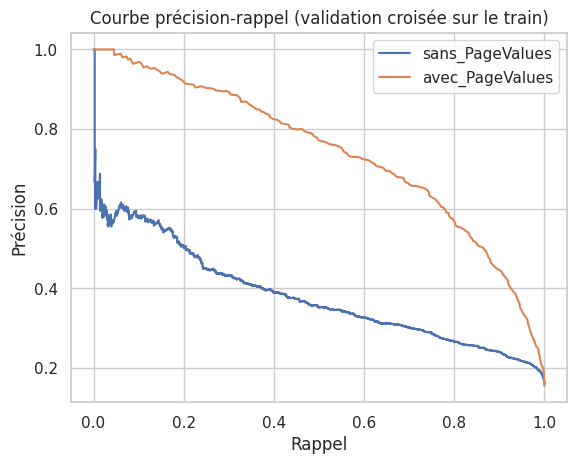

In [27]:
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import cross_val_predict


def choose_threshold(feature_set):
    cfg = BEST[feature_set]
    pipe = make_pipeline(cfg["model"], feature_set, cfg["params"])
    proba = cross_val_predict(pipe, X_train, y_train, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_train, proba)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    i = int(np.argmax(f1[:-1]))
    return float(thresholds[i]), precision, recall, f1


THRESHOLDS = {}
for feature_set in FEATURE_SETS:
    thr, precision, recall, f1 = choose_threshold(feature_set)
    THRESHOLDS[feature_set] = thr
    print(f"{feature_set:16s} seuil = {thr:.3f} | F1 CV au seuil = {f1.max():.3f}")
    plt.plot(recall, precision, label=feature_set)
plt.xlabel("Rappel")
plt.ylabel("Précision")
plt.title("Courbe précision-rappel (validation croisée sur le train)")
plt.legend()
plt.show()

### 5.2 Évaluation unique sur le test

Comme en S5, on mesure chaque modèle **et la référence naïve** (toujours « pas d'achat ») sur le test, avec la classe positive 1 = achat :
- la **matrice de confusion** : `confusion_matrix(...).ravel()` donne, dans l'ordre, VN, FP, FN, VP ;
- la **précision** VP / (VP + FP) : parmi les sessions signalées, la part qui achète vraiment ;
- le **rappel** VP / (VP + FN) : parmi les acheteurs, la part qu'on retrouve ;
- le **F1**, compromis entre les deux, et l'**accuracy** (VP + VN) / total, pour montrer qu'elle ne suffit pas avec 15 % d'achats.

`zero_division=0` évite l'avertissement pour la référence, qui ne prédit jamais d'achat.

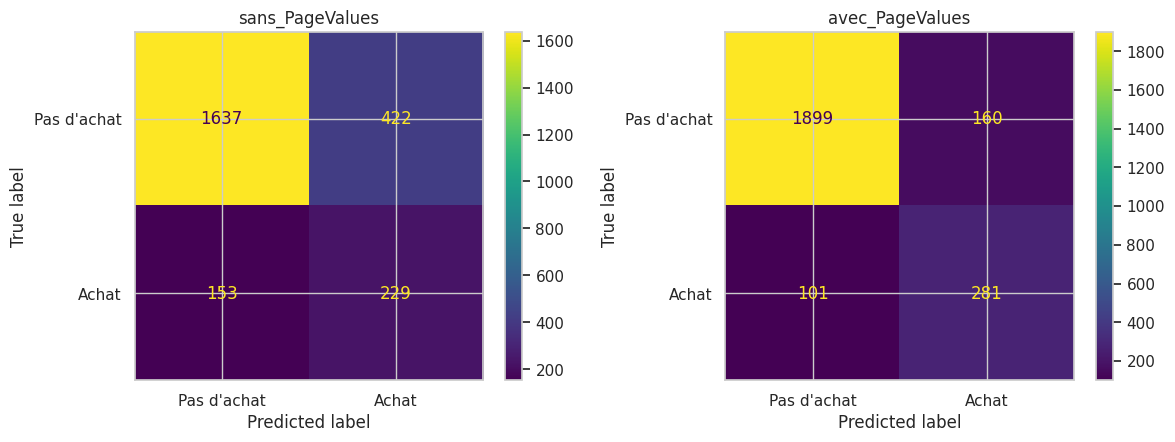

,variables,modele,seuil,VP,FP,FN,VN,accuracy,precision,rappel,f1,auc
0,aucune,Reference_naive,NaN,0,0,382,2059,0.844,0.000,0.000,0.000,0.500
1,sans_PageValues,Gradient_boosting,0.593,229,422,153,1637,0.764,0.352,0.599,0.443,0.785
2,avec_PageValues,Foret_aleatoire,0.323,281,160,101,1899,0.893,0.637,0.736,0.683,0.925


              precision    recall  f1-score   support

 Pas d'achat       0.91      0.80      0.85      2059
       Achat       0.35      0.60      0.44       382

    accuracy                           0.76      2441
   macro avg       0.63      0.70      0.65      2441
weighted avg       0.83      0.76      0.79      2441



In [28]:
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score)


def measure_test(variables, model_name, threshold, y_pred, proba):
    """Les mesures de S5 sur le test : matrice de confusion, accuracy, précision, rappel, F1, plus l'AUC."""
    vn, fp, fn, vp = confusion_matrix(y_test, y_pred).ravel()
    return {"variables": variables, "modele": model_name, "seuil": threshold,
            "VP": int(vp), "FP": int(fp), "FN": int(fn), "VN": int(vn),
            "accuracy": round(accuracy_score(y_test, y_pred), 3),
            "precision": round(precision_score(y_test, y_pred, zero_division=0), 3),
            "rappel": round(recall_score(y_test, y_pred), 3),
            "f1": round(f1_score(y_test, y_pred, zero_division=0), 3),
            "auc": round(roc_auc_score(y_test, proba), 3)}


# Référence naïve à battre : toujours la classe la plus fréquente (« pas d'achat »)
reference = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
metrics = [measure_test("aucune", "Reference_naive", None,
                        reference.predict(X_test), reference.predict_proba(X_test)[:, 1])]

FINAL = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, feature_set in zip(axes, FEATURE_SETS):
    cfg = BEST[feature_set]
    pipe = make_pipeline(cfg["model"], feature_set, cfg["params"]).fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    y_pred = (proba >= THRESHOLDS[feature_set]).astype(int)
    FINAL[feature_set] = {"pipe": pipe, "y_pred": y_pred, "proba": proba}
    metrics.append(measure_test(feature_set, cfg["model"], round(THRESHOLDS[feature_set], 3), y_pred, proba))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, display_labels=["Pas d'achat", "Achat"])
    ax.set_title(feature_set)
plt.tight_layout()
plt.show()

metrics = pd.DataFrame(metrics)
display(metrics)
print(classification_report(y_test, FINAL[DEPLOYED]["y_pred"], target_names=["Pas d'achat", "Achat"]))

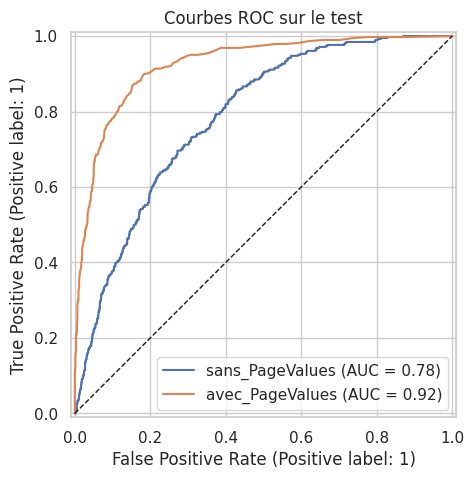

In [29]:
fig, ax = plt.subplots(figsize=(6, 5))
for feature_set in FEATURE_SETS:
    RocCurveDisplay.from_predictions(y_test, FINAL[feature_set]["proba"], name=feature_set, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_title("Courbes ROC sur le test")
plt.show()

### 5.3 Où le modèle se trompe-t-il ?

Rappel (part des acheteurs détectés) par groupe, pour le modèle déployé : par type de visiteur, par mois, et par région.
`Region` est une variable sensible (risque de discrimination, section 1 du README) : on vérifie que le modèle ne sert pas nettement plus mal certaines régions.

In [30]:
errors = X_test.assign(achat=y_test.values, detecte=FINAL[DEPLOYED]["y_pred"])
buyers = errors[errors.achat == 1]
RECALL_GROUPS = {}
for col in ["VisitorType", "Month", "Region"]:
    table = buyers.groupby(col)["detecte"].agg(rappel="mean", acheteurs="size").round(3)
    RECALL_GROUPS[col] = table["rappel"].to_dict()
    display(table.sort_values("rappel"))

,rappel,acheteurs
VisitorType,,
Returning_Visitor,0.540,285
New_Visitor,0.773,97


,rappel,acheteurs
Month,,
Aug,0.357,14
May,0.443,79
Jul,0.467,15
Mar,0.485,33
Jun,0.500,6
Sep,0.526,19
Dec,0.568,37
Oct,0.611,18
Nov,0.752,161


,rappel,acheteurs
Region,,
5,0.429,7
6,0.474,19
7,0.478,23
4,0.548,42
3,0.585,65
2,0.590,39
8,0.600,10
1,0.635,156
9,0.810,21


### 5.3 bis Et sur une période jamais vue ?

Le découpage de la partie 2 est aléatoire : le test contient les mêmes mois que l'entraînement. Il ne dit donc pas comment le modèle se comporte sur une **nouvelle période**, alors que c'est ainsi qu'il sera utilisé.
On le vérifie **sur l'entraînement seulement** (le test n'est pas réutilisé) : pour chaque mois, on entraîne la configuration retenue sur les autres mois, puis on la mesure sur ce mois, jamais vu, avec le seuil de la partie 5.1.
Les mois avec moins de 20 achats sont affichés sans F1 ni rappel : leurs scores varieraient trop par hasard.

In [31]:
from sklearn.model_selection import LeaveOneGroupOut

cfg = BEST[DEPLOYED]
rows_mois = []
for tr, va in LeaveOneGroupOut().split(X_train, y_train, groups=X_train["Month"]):
    pipe = make_pipeline(cfg["model"], DEPLOYED, cfg["params"]).fit(X_train.iloc[tr], y_train.iloc[tr])
    proba = pipe.predict_proba(X_train.iloc[va])[:, 1]
    y_va = y_train.iloc[va]
    y_hat = (proba >= THRESHOLDS[DEPLOYED]).astype(int)
    row = {"mois": X_train["Month"].iloc[va[0]], "sessions": len(va), "achats": int(y_va.sum())}
    if y_va.sum() >= 20:
        row.update(f1=round(f1_score(y_va, y_hat), 3), rappel=round(recall_score(y_va, y_hat), 3),
                   auc=round(roc_auc_score(y_va, proba), 3))
    rows_mois.append(row)

mois_inconnus = pd.DataFrame(rows_mois).set_index("mois").loc[[m for m in ["Feb", "Mar", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
                                                               if m in set(X_train["Month"])]]
display(mois_inconnus)
mesurables = mois_inconnus.dropna(subset=["f1"])
poids = mesurables["achats"] / mesurables["achats"].sum()
print(f"Mois jamais vus : F1 moyen pondéré par les achats = {(mesurables['f1'] * poids).sum():.3f} "
      f"(à comparer au « F1 CV au seuil » affiché en 5.1, obtenu avec un découpage aléatoire)")

,sessions,achats,f1,rappel,auc
mois,,,,,
Feb,144,3,NaN,NaN,NaN
Mar,1500,159,0.328,0.509,0.760
May,2674,286,0.298,0.339,0.777
Jun,225,23,0.185,0.217,0.748
Jul,353,51,0.167,0.157,0.658
Aug,360,62,0.388,0.419,0.713
Sep,354,67,0.304,0.358,0.655
Oct,433,97,0.324,0.340,0.589
Nov,2358,599,0.358,0.371,0.652


Mois jamais vus : F1 moyen pondéré par les achats = 0.334 (à comparer au « F1 CV au seuil » affiché en 5.1, obtenu avec un découpage aléatoire)


### 5.4 Limites

- **Erreurs les plus fréquentes :** sur les 2 441 sessions du test (382 achats), le modèle déployé détecte 60 % des acheteurs (rappel 0,599), mais seules 35 % de ses alertes sont de vrais achats (précision 0,35). Il rate donc 153 acheteurs et donne 422 fausses alertes (matrice de confusion, 5.2) : les fausses alertes sont l'erreur la plus nombreuse, mais la moins grave pour notre utilisateur (une offre proposée pour rien). Son exactitude (0,76) est plus basse que celle de la référence naïve sur le test (0,844) : c'est normal, car la référence ne trouve aucun acheteur.
- **Pourquoi ce seuil :** le seuil (0,593) maximise le F1 en validation croisée. Un seuil plus bas trouverait plus d'acheteurs, mais avec encore plus de fausses alertes : le F1 est le compromis choisi dans le cadrage, car une offre envoyée à tort a aussi un coût.
- **Groupes mal servis :** les visiteurs réguliers (rappel 0,540 sur 285 acheteurs, contre 0,773 pour les 97 nouveaux visiteurs), alors que ce sont les plus nombreux. Selon le mois, le rappel va de 0,357 en août et 0,443 en mai à 0,752 en novembre ; mais plusieurs mois ont moins de 20 acheteurs dans le test (juin : 6, août : 14, juillet : 15, octobre : 18, septembre : 19), donc leurs chiffres changent beaucoup par hasard. Par région, les régions avec au moins 30 acheteurs vont de 0,548 (région 4) à 0,635 (région 1) : pas d'écart net. Les écarts plus grands (0,429 en région 5, 0,810 en région 9) portent sur 7 à 23 acheteurs seulement. Janvier et avril sont absents des données.
- **Nouvelle période (5.3 bis) :** sur un mois jamais vu à l'entraînement, le F1 tombe à 0,334 en moyenne (contre 0,425 en validation croisée aléatoire), avec un rappel souvent autour de 0,35. Le score du test (0,443) est donc optimiste pour un usage sur une nouvelle période : il faut surveiller le modèle et le réentraîner régulièrement (6.2, 6.3).
- **Pendant la visite :** le modèle a appris sur des sessions **terminées** (toutes les pages vues, toutes les durées). En cours de visite, ces valeurs sont encore incomplètes : l'estimation est plus fiable vers la fin de la visite. C'est la même question que pour `PageValues`, à un degré moindre.
- **Usages à éviter :** décider automatiquement à la place d'une personne (le modèle aide à cibler une offre, il ne doit pas refuser une aide à un client) ; fixer des prix différents selon la région ou le type de visiteur ; l'utiliser sur un autre site ou une autre période (janvier, avril) sans le réentraîner ; utiliser en direct la version avec `PageValues`, dont le score (F1 0,683) n'est pas atteignable pendant la visite.

# Partie 6 · Déploiement (étape 6)

### 6.1 Export pour l'application

In [32]:
import joblib

deployed_cols = FEATURE_SETS[DEPLOYED]
num_cols = [c for c in deployed_cols if c in NUM_COLS + [LEAKY_COL]]
bundle = {
    "pipeline": FINAL[DEPLOYED]["pipe"],
    "threshold": THRESHOLDS[DEPLOYED],
    "feature_set": DEPLOYED,
    "features": deployed_cols,
    "num_cols": num_cols,
    "cat_cols": CAT_COLS,
    "bool_cols": BOOL_COLS,
    # bornes vues à l'entraînement : l'application refuse ce qui sort de ce domaine
    "schema": {
        "num": {c: [float(X_train[c].min()), float(X_train[c].max())] for c in num_cols},
        "cat": {c: sorted(X_train[c].unique().tolist()) for c in CAT_COLS},
    },
    "metrics_test": metrics[metrics.variables == DEPLOYED].iloc[0].to_dict(),
    "rappel_par_groupe": {"VisitorType": RECALL_GROUPS["VisitorType"]},   # partie 5.3
    "versions": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
joblib.dump(bundle, "model.joblib")

# requirements.txt avec les versions EXACTES de cet environnement (évite les erreurs de chargement)
Path("requirements.txt").write_text(
    "streamlit\n"
    f"scikit-learn=={sklearn.__version__}\n"
    f"pandas=={pd.__version__}\n"
    f"numpy=={np.__version__}\n"
    f"joblib=={joblib.__version__}\n"
)
print(Path("requirements.txt").read_text())
print("Modèle exporté :", bundle["metrics_test"])

try:
    from google.colab import files
    files.download("model.joblib")
    files.download("requirements.txt")
except ImportError:
    print("Hors Colab : fichiers écrits dans", Path.cwd())

streamlit
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
joblib==1.6.0

Modèle exporté : {'variables': 'sans_PageValues', 'modele': 'Gradient_boosting', 'seuil': 0.593, 'VP': 229, 'FP': 422, 'FN': 153, 'VN': 1637, 'accuracy': 0.764, 'precision': 0.352, 'rappel': 0.599, 'f1': 0.443, 'auc': 0.785}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 6.1 bis Tester l'application avant de la publier

Comme à l'étape 6 du TP de S5 : `AppTest` exécute `app.py` comme un utilisateur (il remplit les champs et clique), sans ouvrir de navigateur.
On teste l'application du dépôt GitHub **avec le `model.joblib` qu'on vient d'écrire**, dans un dossier temporaire : une session sans page doit être refusée, une session normale doit recevoir une probabilité.

In [33]:
import os
import shutil
import subprocess
import sys
import tempfile
import urllib.request

try:
    import streamlit
except ImportError:   # Streamlit n'est pas installé d'office dans Colab (environ 30 secondes)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "streamlit"], check=True)
    import streamlit
from streamlit.testing.v1 import AppTest

APP_URL = "https://raw.githubusercontent.com/khaledmnejja/projet-achat-en-ligne/main/app/app.py"
test_dir = Path(tempfile.mkdtemp())
local_app = Path("../app/app.py")   # copie locale du dépôt, si le notebook tourne hors de Colab
if local_app.exists():
    shutil.copy(local_app, test_dir / "app.py")
else:
    urllib.request.urlretrieve(APP_URL, test_dir / "app.py")
shutil.copy("model.joblib", test_dir / "model.joblib")
app_file = os.path.abspath(test_dir / "app.py")


def set_number(at, label, value):
    next(w for w in at.number_input if w.label == label).set_value(value)


def submit(at):
    next(b for b in at.button if b.label.startswith("Estimer")).click()
    return at.run()


# 1. Session vide : l'application doit la refuser, sans prédiction
at = submit(AppTest.from_file(app_file, default_timeout=60).run())
assert not at.exception, at.exception
print("Session sans page :", [e.value for e in at.error])
assert at.error and not at.metric

# 2. Session normale : 12 pages produits pendant 8 minutes
at = AppTest.from_file(app_file, default_timeout=60).run()
set_number(at, "Pages produits vues", 12)
set_number(at, "Temps sur les pages produits (s)", 482.5)
at = submit(at)
assert not at.exception and not at.error, (at.exception, at.error)
print("Session normale    :", at.metric[0].value, "·", (at.success or at.warning)[0].value)
print("Limites affichées  :", at.info[0].value[:120], "…")

2026-11-27 17:38:06.854 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-27 17:38:08.274 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Session sans page : ['Une session doit contenir au moins une page vue.']
Session normale    : 38% · Achat peu probable d'après le modèle.
Limites affichées  : **Limites du modèle.** Entraîné sur les sessions d'un seul site marchand pendant une année, sans janvier ni avril. Sur n …


### 6.2 Surveiller le modèle en service

Une fois en ligne, le modèle ne sait pas s'il se trompe : on ne connaît l'achat qu'**après** la visite.
On surveille donc trois choses, sur chaque lot de sessions (par exemple chaque mois) :

1. **Les entrées** : les sessions ressemblent-elles encore à celles de l'entraînement ?
   - *PSI* (indice de stabilité) de chaque variable numérique : moins de 0,1 = stable,
     0,1 à 0,25 = à surveiller, plus de 0,25 = forte dérive ;
   - part de catégories jamais vues (un nouveau navigateur, un nouveau code de trafic) ;
   - part de valeurs hors des bornes vues à l'entraînement.
2. **Les sorties** : la part de sessions que le modèle annonce comme « achat ».
3. **La qualité réelle**, dès que les achats sont connus : rappel et F1 du lot.

Ci-dessous, on **simule** la production en découpant le test par mois. Le test a déjà servi à
l'évaluation unique (5.2) : ici, on ne choisit rien, on montre seulement à quoi ressemble le suivi.

In [34]:
def psi(reference, current, bins=10):
    """Population Stability Index : 0 = même distribution ; plus de 0,25 = forte dérive."""
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    ref = np.histogram(reference, edges)[0] / len(reference)
    cur = np.histogram(current, edges)[0] / len(current)
    ref, cur = np.clip(ref, 1e-4, None), np.clip(cur, 1e-4, None)   # évite log(0)
    return float(np.sum((cur - ref) * np.log(cur / ref)))


ALERTS = {"psi": 0.25, "inconnues": 0.05, "baisse_rappel": 0.10}   # seuils d'alerte
MIN_SESSIONS, MIN_ACHATS = 100, 20      # en dessous, le lot est trop petit pour conclure
CALENDAR_COLS = ["SpecialDay"]          # dépend du mois par construction : ce n'est pas une dérive
RAPPEL_TEST = bundle["metrics_test"]["rappel"]


def monitoring_report(batch, y_true=None, reference=X_train, model=bundle):
    """Rapport de suivi d'un lot de sessions (y_true seulement si les achats sont déjà connus)."""
    schema = model["schema"]
    psis = {c: psi(reference[c], batch[c]) for c in model["num_cols"] if c not in CALENDAR_COLS}
    worst = max(psis, key=psis.get)
    inconnues = np.mean([~batch[c].isin(schema["cat"][c]) for c in model["cat_cols"]], axis=0)
    hors_bornes = np.mean([(batch[c] < lo) | (batch[c] > hi) for c, (lo, hi) in schema["num"].items()], axis=0)
    y_pred = (model["pipeline"].predict_proba(batch[model["features"]])[:, 1] >= model["threshold"]).astype(int)
    report = {"sessions": len(batch),
              "psi_max": round(psis[worst], 3), "variable_psi_max": worst,
              "part_inconnues": round(float((inconnues > 0).mean()), 3),
              "part_hors_bornes": round(float((hors_bornes > 0).mean()), 3),
              "achats_predits": round(float(y_pred.mean()), 3)}
    alertes = []
    if len(batch) < MIN_SESSIONS:
        alertes.append("lot trop petit")
    else:
        if report["psi_max"] > ALERTS["psi"]:
            alertes.append(f"dérive de {worst}")
        if report["part_inconnues"] > ALERTS["inconnues"]:
            alertes.append("catégories inconnues")
    if y_true is not None:
        report["achats_reels"] = round(float(np.mean(y_true)), 3)
        if np.sum(y_true) >= MIN_ACHATS:
            report["rappel"] = round(recall_score(y_true, y_pred), 3)
            report["f1"] = round(f1_score(y_true, y_pred), 3)
            if report["rappel"] < RAPPEL_TEST - ALERTS["baisse_rappel"]:
                alertes.append("baisse du rappel")
    report["alerte"] = ", ".join(alertes) or "aucune"
    return report


# Simulation : un lot par mois du test (ordre du calendrier)
MONTH_ORDER = ["Feb", "Mar", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
suivi = pd.DataFrame({m: monitoring_report(X_test[X_test.Month == m], y_test[X_test.Month == m])
                      for m in MONTH_ORDER if (X_test.Month == m).any()}).T
print(f"Référence : {y_train.mean():.3f} d'achats à l'entraînement, rappel sur le test = {RAPPEL_TEST}")
display(suivi)

Référence : 0.156 d'achats à l'entraînement, rappel sur le test = 0.599


,sessions,psi_max,variable_psi_max,part_inconnues,part_hors_bornes,achats_predits,achats_reels,alerte,rappel,f1
Feb,37,2.799,Administrative,0.0,0.0,0.0,0.0,lot trop petit,NaN,NaN
Mar,360,0.203,ProductRelated,0.003,0.0,0.158,0.092,baisse du rappel,0.485,0.356
May,655,0.038,ProductRelated,0.0,0.0,0.163,0.121,baisse du rappel,0.443,0.376
Jun,60,0.782,ExitRates,0.0,0.0,0.1,0.1,lot trop petit,NaN,NaN
Jul,79,0.248,ExitRates,0.0,0.0,0.228,0.19,lot trop petit,NaN,NaN
Aug,73,0.169,Administrative_Duration,0.0,0.0,0.219,0.192,lot trop petit,NaN,NaN
Sep,94,0.2,Administrative_Duration,0.0,0.0,0.213,0.202,lot trop petit,NaN,NaN
Oct,116,0.37,Administrative,0.0,0.0,0.379,0.155,dérive de Administrative,NaN,NaN
Nov,624,0.109,ProductRelated,0.0,0.0,0.508,0.258,aucune,0.752,0.506
Dec,343,0.07,ProductRelated,0.0,0.0,0.192,0.108,aucune,0.568,0.408


**Lecture.** Les lots de moins de 100 sessions, ou de moins de 20 achats
pour le rappel, ne déclenchent rien : leurs scores varient trop par hasard. `SpecialDay` est exclue du PSI,
car elle dépend du mois par construction (non nulle seulement en février et mai).

- **Mois en alerte et raison :** 3 mois sur 10. En **mars** (rappel 0,485) et en **mai** (0,443), le rappel baisse nettement par rapport à la référence de 0,599 : ce sont des mois où l'on achète moins (9,2 % et 12,1 % d'achats). En **octobre**, c'est une dérive des entrées : `Administrative` a un PSI de 0,37 (plus de 0,25 = forte dérive). Cinq lots sont trop petits pour conclure (février, juin, juillet, août, septembre), même si février a un PSI très élevé (2,8) sur seulement 37 sessions. Novembre et décembre ne déclenchent aucune alerte.
- **Part d'achats annoncés comparée à la part réelle :** le modèle annonce presque toujours plus d'achats qu'il n'y en a, car son seuil a été choisi pour le F1 et il utilise `class_weight="balanced"`. L'écart est le plus grand en novembre (50,8 % annoncés contre 25,8 % réels) et en octobre (37,9 % contre 15,5 %). Seuls février (0 % / 0 %) et juin (10 % / 10 %) correspondent. Cette part se calcule tout de suite, sans attendre de connaître les achats : si elle s'écarte d'un coup de son niveau habituel, c'est un premier signal à surveiller.

### 6.3 Réentraîner le modèle

**Quand ?** Dès qu'une alerte du suivi (6.2) se répète deux lots de suite, et au moins une fois par
saison (les achats varient beaucoup selon le mois, et janvier et avril manquent dans nos données).

**Comment ?** On ne change pas la méthode, seulement les données. C'est la boucle du workflow :
retour à l'étape 2 (Préparation) avec les nouvelles sessions dont l'achat est connu.

1. ajouter les nouvelles sessions, puis `clean()` (mêmes règles, doublons retirés) ;
2. réentraîner la configuration `BEST` et rechoisir le seuil **en validation croisée** ;
3. comparer l'ancien et le nouveau modèle sur les sessions **les plus récentes**, jamais vues par l'un ou l'autre ;
4. ne remplacer `model.joblib` que si le nouveau modèle fait mieux (F1 « achat »), et garder l'ancien
   fichier pour pouvoir revenir en arrière ;
5. si les données ont trop changé (nouveaux mois, nouveaux types de visiteurs), refaire aussi
   l'étape 4 (`GridSearchCV`).

In [35]:
def retrain(X_new, y_new, feature_set=DEPLOYED):
    """Réentraîne la configuration retenue et rechoisit le seuil en validation croisée."""
    cfg = BEST[feature_set]
    pipe = make_pipeline(cfg["model"], feature_set, cfg["params"])
    proba = cross_val_predict(pipe, X_new, y_new, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_new, proba)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    return pipe.fit(X_new, y_new), float(thresholds[int(np.argmax(f1[:-1]))])


def should_replace(current, candidate, X_recent, y_recent):
    """Ancien contre nouveau modèle, sur des sessions récentes qu'aucun des deux n'a vues."""
    scores = {}
    for name, (pipe, thr) in {"actuel": current, "nouveau": candidate}.items():
        y_pred = (pipe.predict_proba(X_recent)[:, 1] >= thr).astype(int)
        scores[name] = round(f1_score(y_recent, y_pred), 3)
    return scores["nouveau"] > scores["actuel"], scores


# Vérification : relancée sur les mêmes données, la procédure redonne le même seuil que la partie 5.
_, thr_check = retrain(X_train, y_train)
assert abs(thr_check - THRESHOLDS[DEPLOYED]) < 1e-9, "La procédure de réentraînement n'est pas reproductible"
print(f"Réentraînement reproductible : seuil {thr_check:.3f} = seuil de la partie 5")

Réentraînement reproductible : seuil 0.593 = seuil de la partie 5


## Bilan J3

- **Modèle déployé, seuil et scores sur le test :** gradient boosting sans `PageValues` (`learning_rate = 0.05`, `max_depth = 6`), avec un seuil de **0,593** choisi en validation croisée sur l'entraînement. Sur le test, mesuré une seule fois : **F1 0,443**, rappel 0,599, précision 0,35, AUC 0,785. Le F1 du test est proche de celui de la validation croisée (0,425) : le modèle ne semble pas surappris. Sur un mois jamais vu (5.3 bis), il descend à 0,334 : c'est la vraie limite pour un usage dans le temps. Pour comparer, la forêt aléatoire avec `PageValues` (seuil 0,323) obtient F1 0,683, rappel 0,736, AUC 0,925.
- **Pourquoi la variante sans `PageValues` :** c'est la seule dont toutes les entrées sont connues pendant la visite. La version avec `PageValues` a de meilleurs scores, mais elle les doit à une variable calculée à partir des achats : en direct, elle ne ferait pas aussi bien. On préfère un modèle moins bon mais honnête sur ce qu'il peut vraiment faire.
- ✅ Référence naïve mesurée sur le test avec les mêmes mesures (5.2) : accuracy 0,844 mais aucun acheteur trouvé (rappel et F1 nuls).
- ✅ Application testée avec `AppTest` avant publication (6.1 bis).
- ✅ `model.joblib` et `requirements.txt` copiés dans le dossier `app/` (l'application lit aussi le rappel par type de visiteur dans `model.joblib`), et tests de l'application dans `app/test_app.py`.